# 03 · Entender la cohorte completa antes de entrenar redes

Estudiamos todas las imágenes de las 26 prendas que han superado los controles. Sus tamaños de clase son diferentes: **no las igualamos mediante un cupo**. Exploramos fotos de train y medimos baselines en validation. No cargamos fotografías ni predicciones de test.

La cohorte corresponde al repertorio elegido y a sus controles de calidad; no es todo el catálogo ni una medida de demanda comercial.

## Papel de este EDA en las vías del proyecto

Según nuestra interpretación de las pistas recogidas en clase, la prioridad es entender el problema y disponer de referencias que podamos explicar, no maximizar una puntuación. Los baselines clásicos permiten medir qué señal existe antes de aprender representaciones. No exigimos que todas las redes los superen: un resultado peor también informa sobre optimización, representación o tamaño muestral. El mapa de scratch, preentrenamiento y extensiones está en 01. Aquí se trabajará con train para explorar y validation para comparar, sin inspeccionar el test para tomar decisiones.

## 1. Protocolo, publicación y entorno

Macro-F1 es la métrica primaria. Accuracy, resultados por clase y coste completan la interpretación. El azar uniforme (1/26) es una expectativa teórica, no nuestro único baseline. El dummy aprende la clase mayoritaria de train; el segundo baseline será regresión logística sobre histogramas de color, que no modelan la disposición espacial. No se ajustan sus hiperparámetros buscando el mejor resultado en validation.

In [4]:
from pathlib import Path
import sys,json,time,hashlib
import base64
from html import escape
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown, HTML, Image as DisplayImage
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib','inline')
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/data/local_dataset.py').is_file())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'src/data'))
from notebook_utils import setup,styled,save_figure,es,BLUE,ORANGE
from data_contract import sha256
setup()
protocol=json.loads((ROOT/'config/experimental_protocol_v1.json').read_text())
output=ROOT/'data/processed'
pointer=json.loads((output/'CURRENT.json').read_text())
run=output/pointer['run_dir']
checks=json.loads((run/'checksums.json').read_text())
assert sha256(run/'image_manifest.csv.gz')==checks['image_manifest.csv.gz']
manifest=pd.read_csv(run/'image_manifest.csv.gz',dtype={'article_id':'string','product_code':'string','group_id':'string'},keep_default_na=False)
train=manifest.loc[manifest.split.eq('train')].copy()
validation=manifest.loc[manifest.split.eq('validation')].copy()
labels=json.loads((run/'labels.json').read_text())
names=sorted(labels,key=labels.get)
expected_scope=json.loads((ROOT/'config/local_images_v1.json').read_text())
assert set(names)==set(expected_scope['include_classes']), 'Ejecutar 02 con el alcance vigente antes del EDA'
RESULTS=ROOT/'results/metrics/03_eda';RESULTS.mkdir(parents=True,exist_ok=True)
SEED=42
assert set(train.group_id).isdisjoint(validation.group_id)
display(Markdown(f"**Publicación:** `{run.name}` · Train: {es(len(train))} · Validation: {es(len(validation))}."))
display(styled(pd.Series(protocol['default_loss'],name='Pérdida inicial de las futuras redes').to_frame()))

**Publicación:** `20261123T181635-92a8fcea` · Train: 51.791 · Validation: 11.583.

Referencia,Pérdida inicial de las futuras redes
name,cross_entropy
class_weights,No


## 2. Cuántas fotos conserva cada clase

La tabla sigue la selección: fotos válidas del tipo elegido, fotos que conservamos tras los controles y porcentaje de cada clase en la cohorte. Las diferencias responden a incidencias y duplicados; no a un objetivo de igualar frecuencias. El número final sale de las reglas.

Las frecuencias describen las prendas seleccionadas después de los controles. Validation y test mantienen grupos completos y proporciones de clase aproximadas; no reponderamos predicciones de una muestra equilibrada para simular otra población.

In [5]:
selected=manifest.loc[manifest.split.ne('excluded')]
valid_scope=manifest.loc[manifest.image_valid & manifest.label.isin(names)]
counts=pd.DataFrame({'Válidas en origen':valid_scope.label.value_counts(),'Conservadas':selected.label.value_counts()}).loc[names]
counts['Conservadas (%)']=100*counts.Conservadas/counts.Conservadas.sum()
counts['Retenidas de las válidas (%)']=100*counts.Conservadas/counts['Válidas en origen']
display(styled(counts,2))
counts.to_csv(RESULTS/'sampling_distribution.csv')
priors=(counts.Conservadas/counts.Conservadas.sum()).to_dict()
(RESULTS/'eligible_population_priors.json').write_text(json.dumps({'population':'all selected garment types after common quality checks, no caps','priors':priors,'status':'descriptive cohort frequencies, not demand or entire catalog'},indent=2))
weights=json.loads((run/'training_class_weights.json').read_text())
display(Markdown(f"Pesos opcionales de la pérdida: **{es(min(weights.values()),3)} a {es(max(weights.values()),3)}**. Con frecuencias desiguales pueden alejarse de uno; la referencia sigue sin pesos y H4 medirá su efecto."))

Clase,Válidas en origen,Conservadas,Conservadas (%),Retenidas de las válidas (%)
Blazer,1.108,1.096,"1,47","98,92"
Blouse,3.975,3.934,"5,28","98,97"
Bodysuit,911,906,"1,22","99,45"
Cardigan,1.546,1.539,"2,07","99,55"
Coat,460,460,"0,62",100
Costumes,89,65,"0,09","73,03"
Dress,10.348,10.297,"13,82","99,51"
Dungarees,309,293,"0,39","94,82"
Garment Set,1.319,1.301,"1,75","98,64"
Hoodie,2.356,2.283,"3,06","96,90"


Pesos opcionales de la pérdida: **0,266 a 46,325**. Con frecuencias desiguales pueden alejarse de uno; la referencia sigue sin pesos y H4 medirá su efecto.

## 3. Revisión visual sistemática de train

Elegimos hasta ocho grupos independientes por clase, con un representante por grupo. Con 26 tipos serían como máximo 208 fotos; si una clase tiene menos grupos de train, se informa el número real y se revisan los disponibles. Esto es una muestra para inspección, no un recorte del dataset de entrenamiento.

La pauta es la misma para todas las etiquetas, incluida Top. La muestra se fija con semilla antes de examinar errores del modelo. La galería permite revisar contorno, textura, fondo y presentación; no verifica automáticamente edad, pose o corrección de etiquetas. Las anotaciones pendientes no son observaciones confirmadas.
**Prenda completa frente a foto de detalle.** Una imagen legible y correctamente
etiquetada puede mostrar solo un cuello, una manga o la textura. Los controles
actuales no distinguen esas fotografías de las vistas completas. En la revisión
manual, anotamos `prenda completa`, `detalle / prenda parcial` o `dudosa` en
`pose_or_presentation`. No son anotaciones automáticas ni motivos de descarte todavía.
Antes de cambiar el filtrado, contaremos estos casos por clase y fijaremos una
regla común acorde al objetivo de clasificar prendas. Si cambia la selección,
habrá que volver a preparar y validar el conjunto; aquí no lo modificamos.

La galería muestra miniaturas de tamaño fijo, sin recortar ni ampliar la foto.
Cada bloque se puede desplegar; no es necesario mostrar las 208 imágenes a la vez.


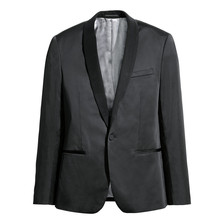
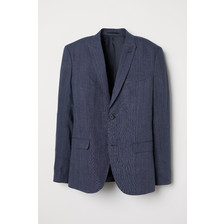
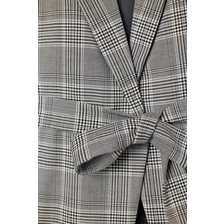
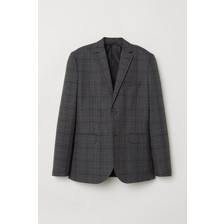
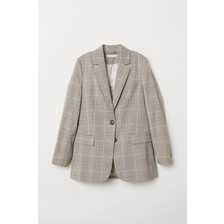
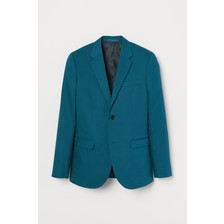
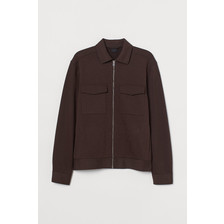
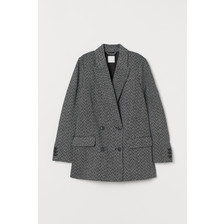
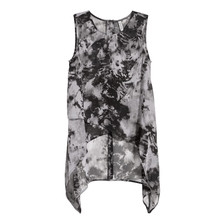
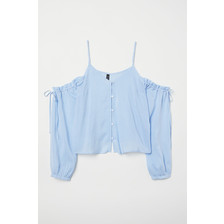
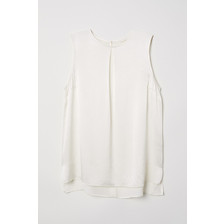
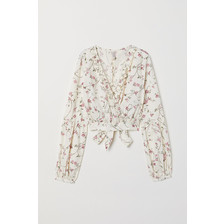
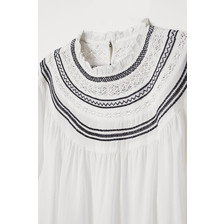
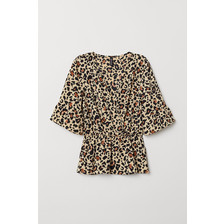
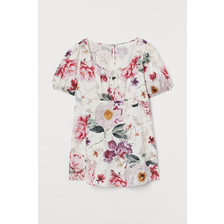
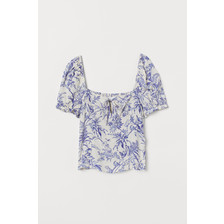
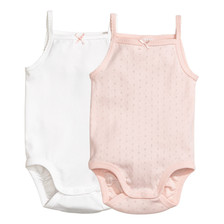
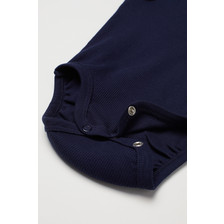
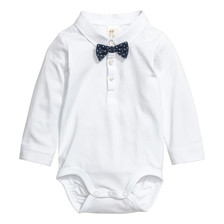
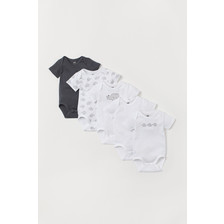
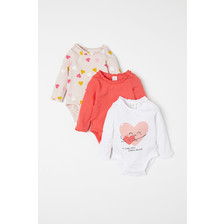
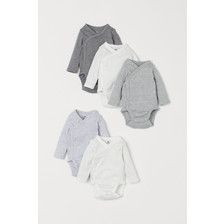
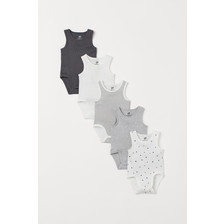
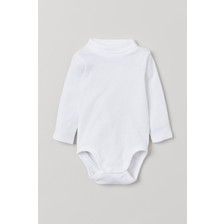


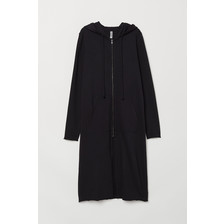
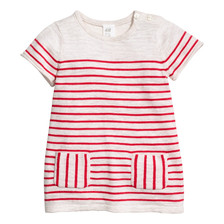
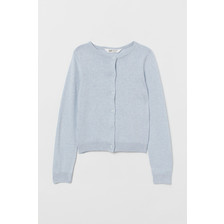
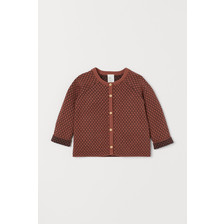
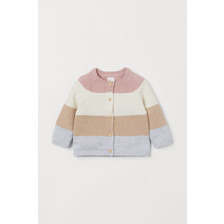
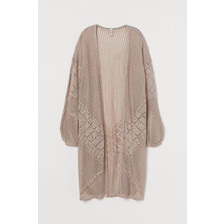
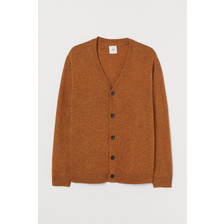
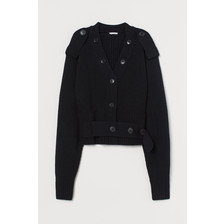
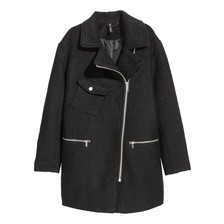
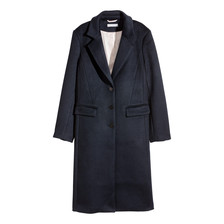
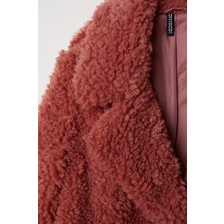
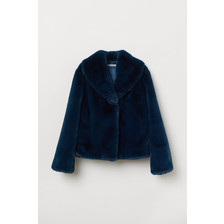
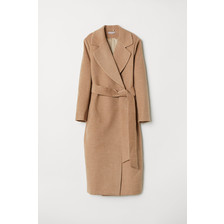
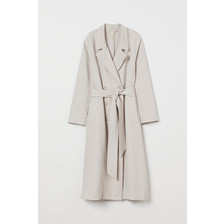
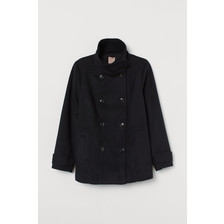
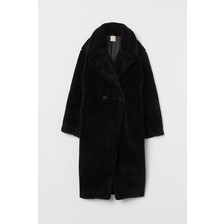
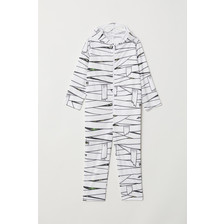
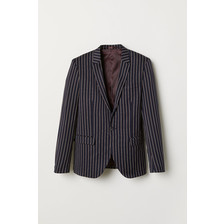
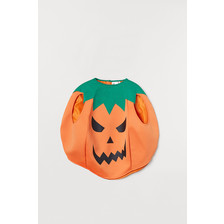
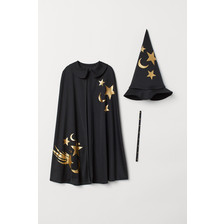
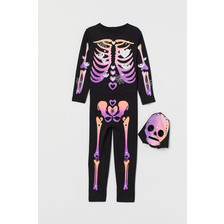
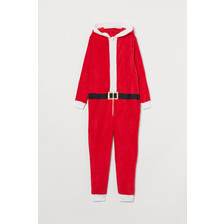
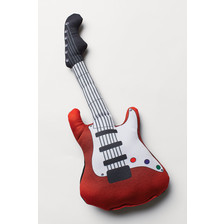
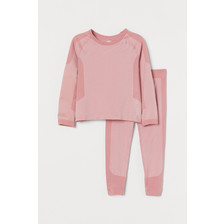


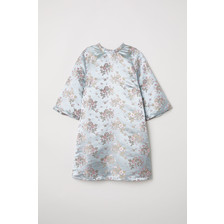
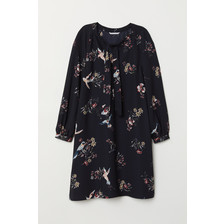
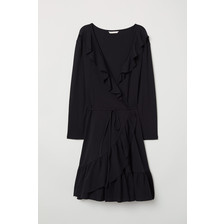
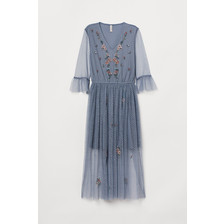
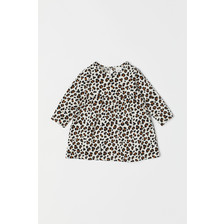
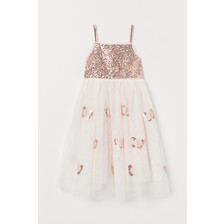
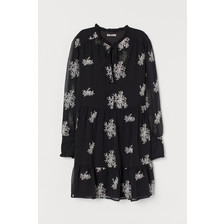
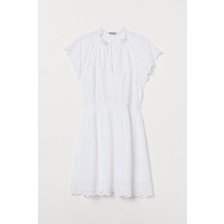
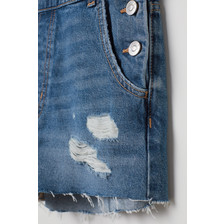
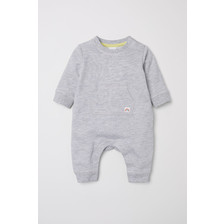
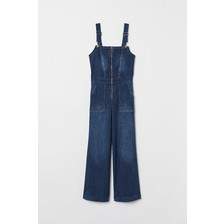
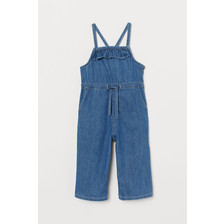
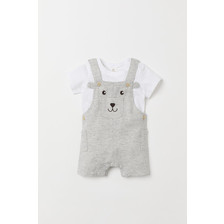
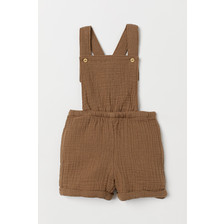
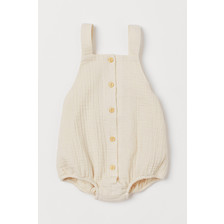
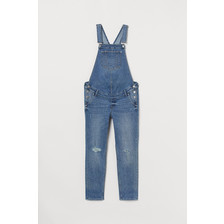
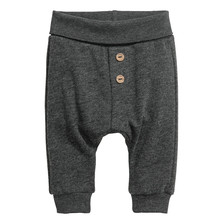
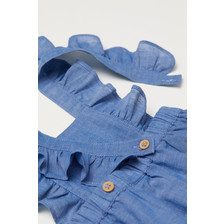
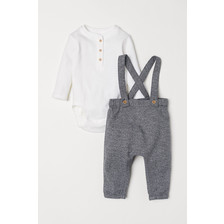
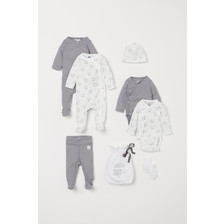
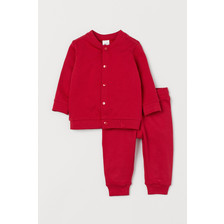
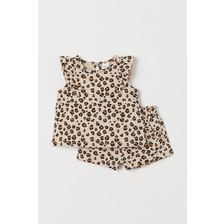
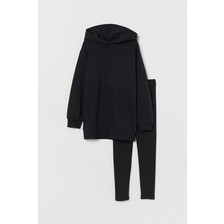
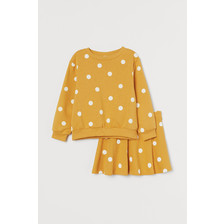


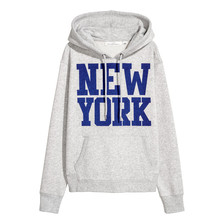
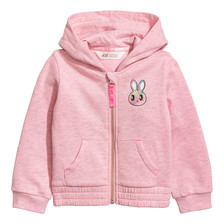
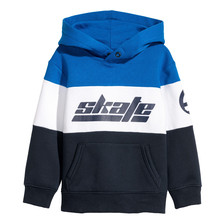
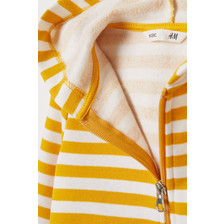
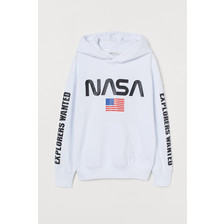
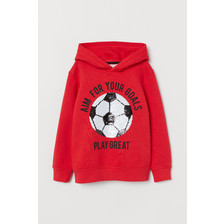
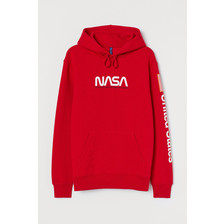
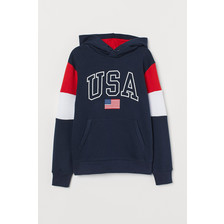
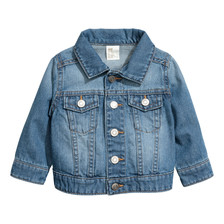
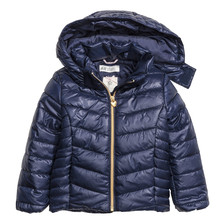
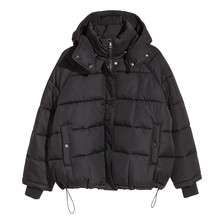
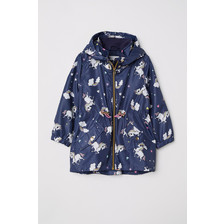
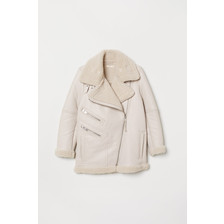
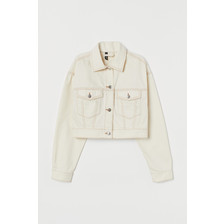
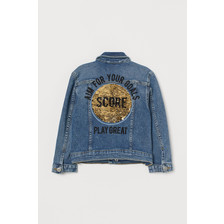
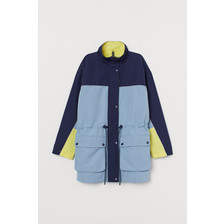
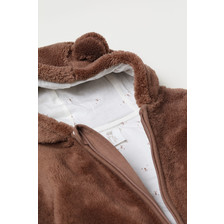
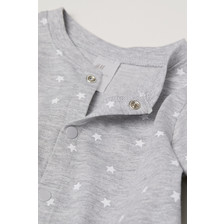
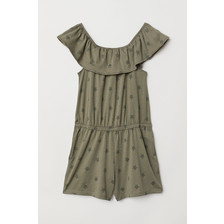
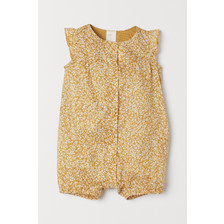
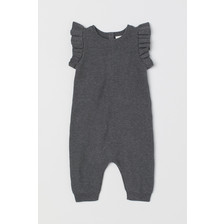
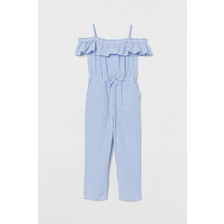
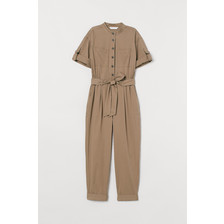
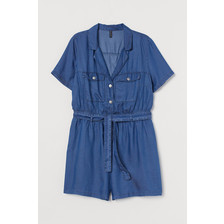


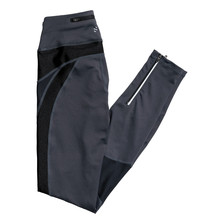
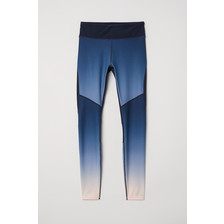
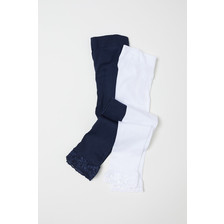
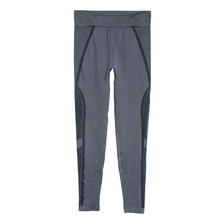
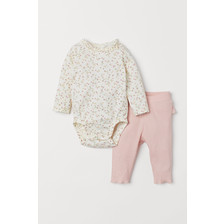
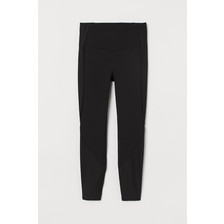
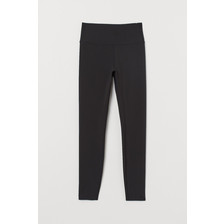
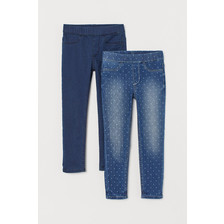
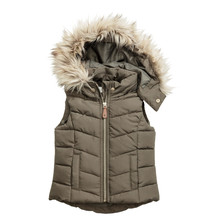
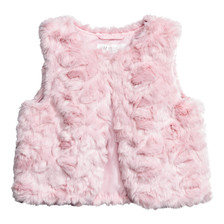
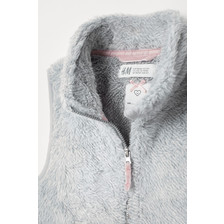
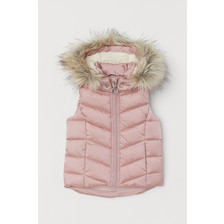
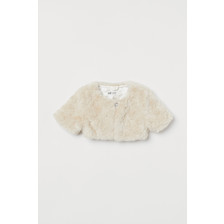
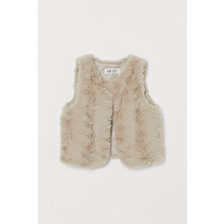
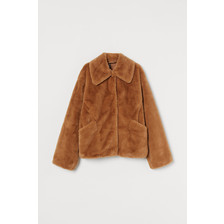
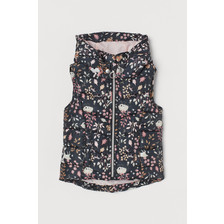
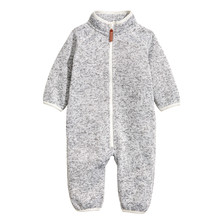
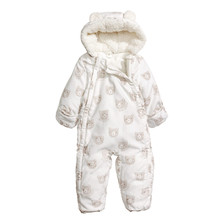
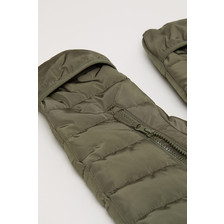
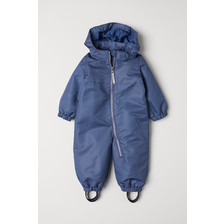
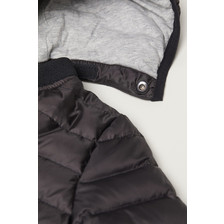
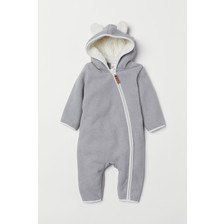
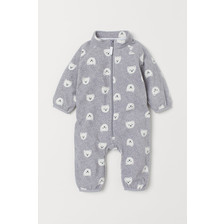
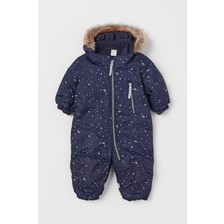


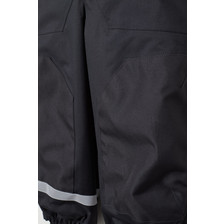
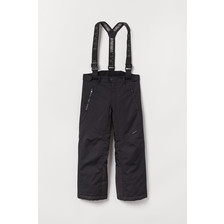
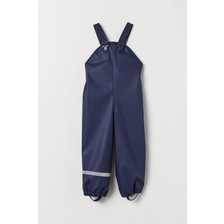
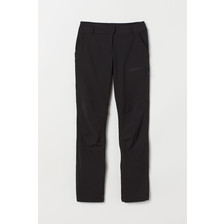
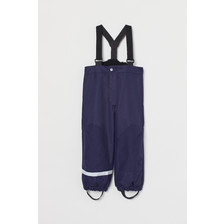
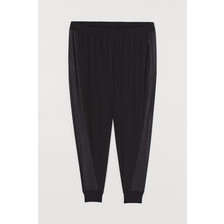
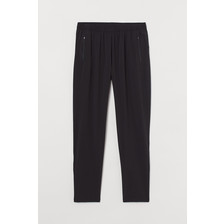
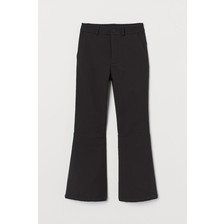
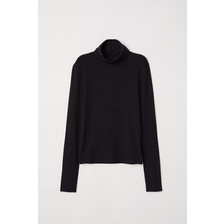
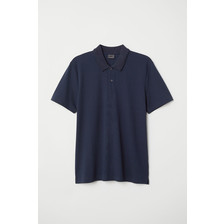
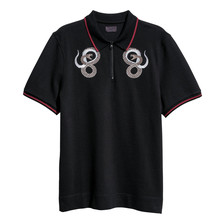
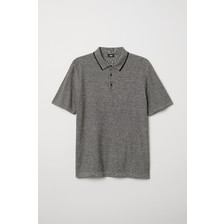
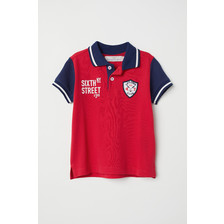
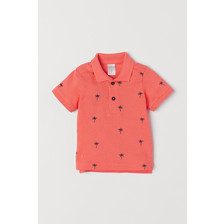
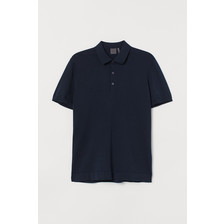
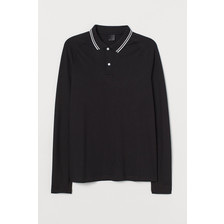
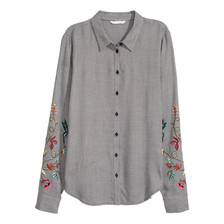
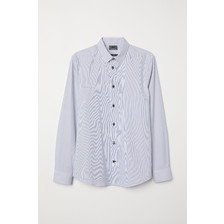
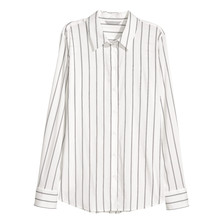
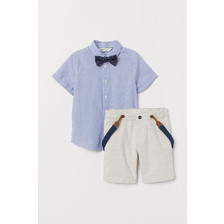
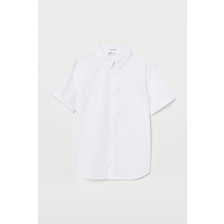
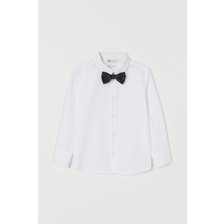
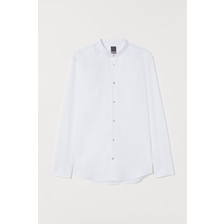
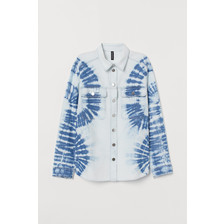


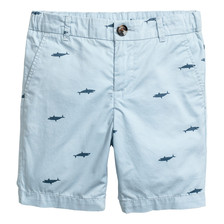
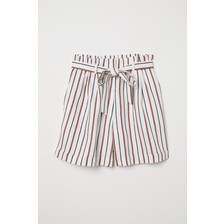
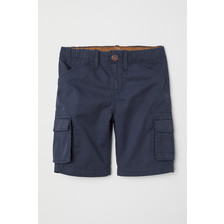
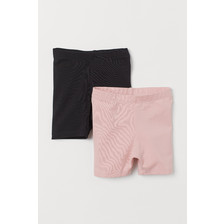
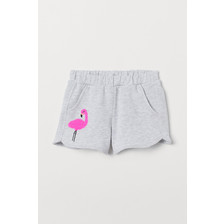
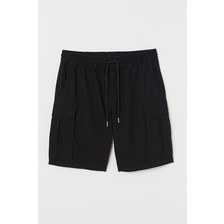
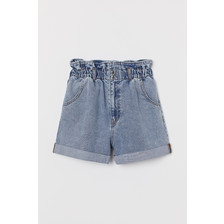
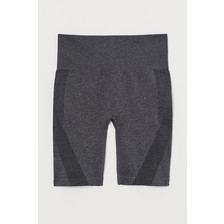
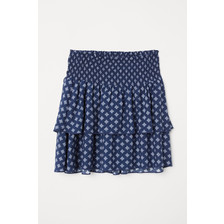
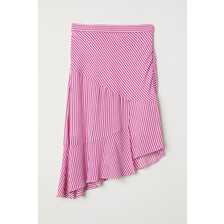
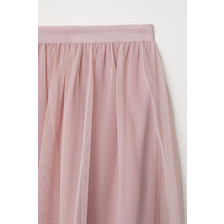
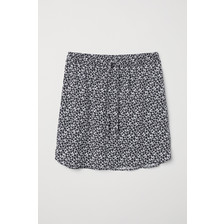
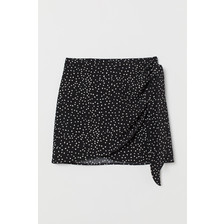
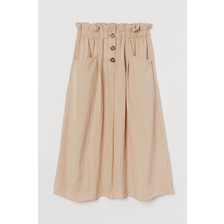
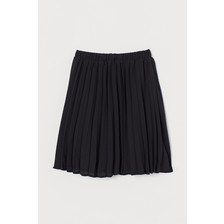
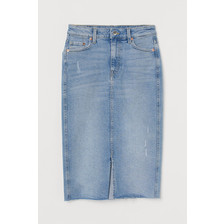
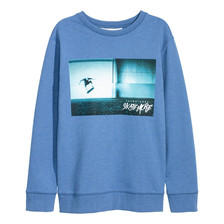
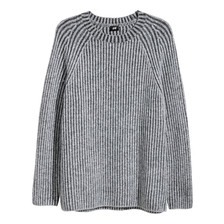
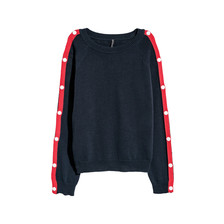
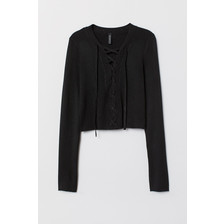
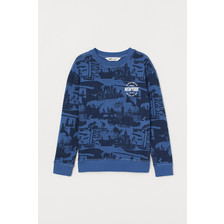
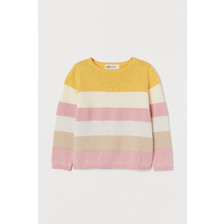
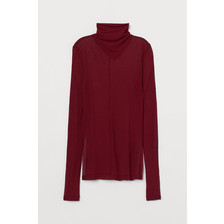
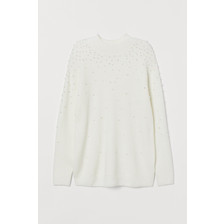


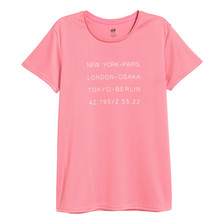
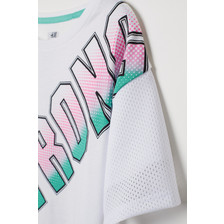
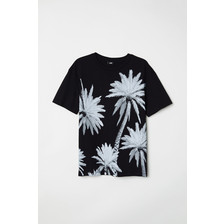
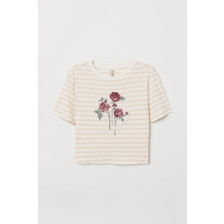
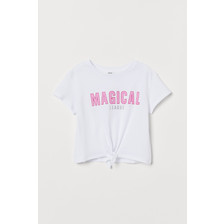
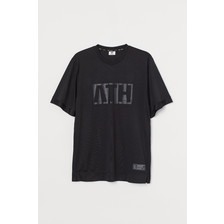
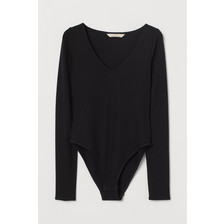
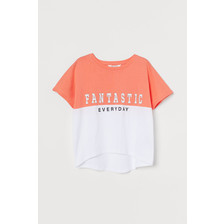
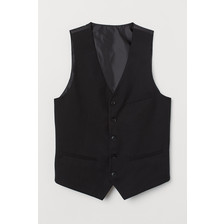
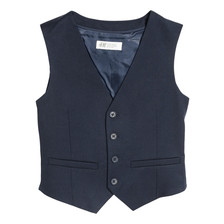
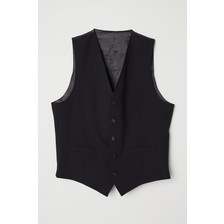
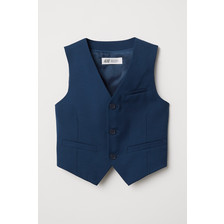
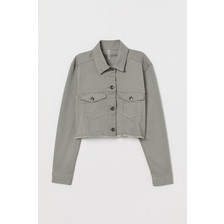
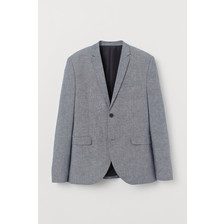
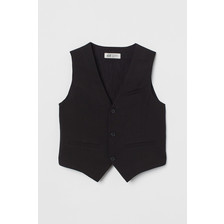
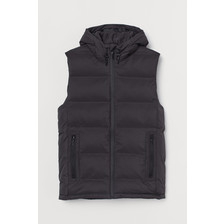
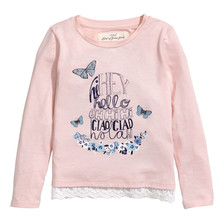
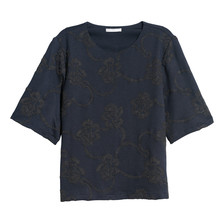
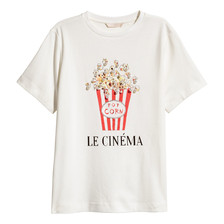
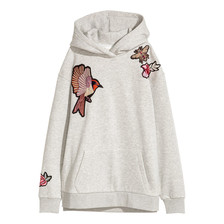
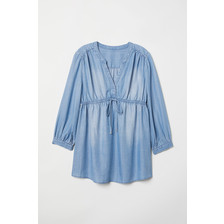
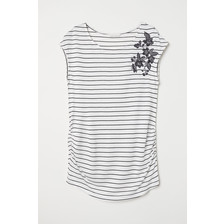
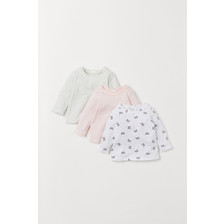
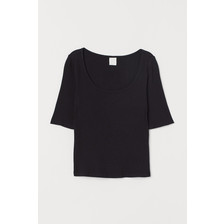


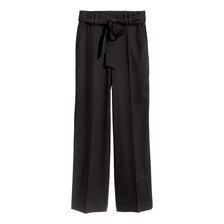
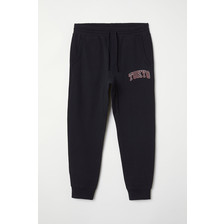
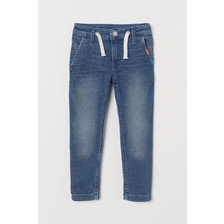
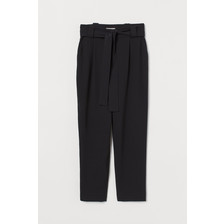
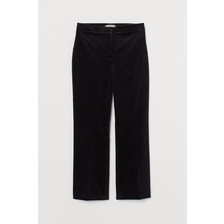
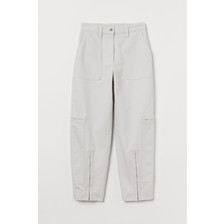
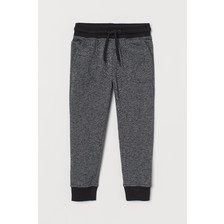
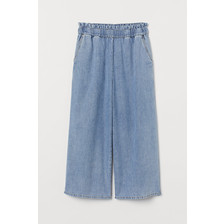
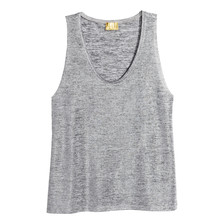
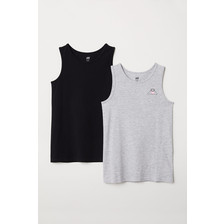
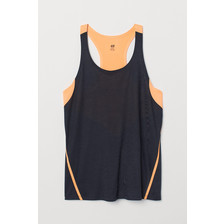
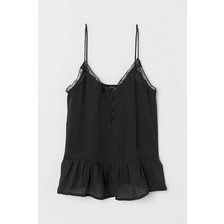
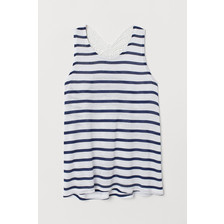
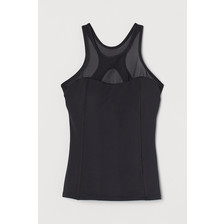
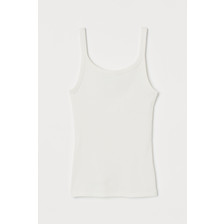
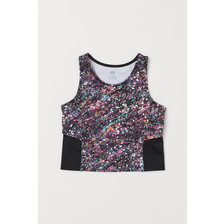

**Muestra de revisión:** 208 productos. **Plantilla:** `results\metrics\03_eda\training_visual_review_79662d323f1d.csv`. Las anotaciones pendientes no se presentan como observaciones confirmadas.

In [6]:
review=[]
review_per_class=int(protocol['class_review']['training_review_products_per_class'])
for label,part in train.groupby('label',sort=True):
    representatives=part.sort_values('article_id').drop_duplicates('group_id')
    review.append(representatives.sample(n=min(review_per_class,len(representatives)),random_state=SEED))
review=pd.concat(review).sort_values(['label','article_id'])
assert len(review)==review.group_id.nunique()
assert review.groupby('label').size().le(review_per_class).all()
review_key=sha256(run/'image_manifest.csv.gz')[:12]
review_path=RESULTS/f'training_visual_review_{review_key}.csv'
columns=['article_id','product_code','group_id','label','image_path']
if not review_path.exists():
    annotation=review[columns].copy()
    for field in ['background_type','pose_or_presentation','label_consistency','uncertainty','notes']:
        annotation[field]='pending'
    annotation.to_csv(review_path,index=False)
else:
    existing=pd.read_csv(review_path,dtype={'article_id':'string'})
    assert set(existing.article_id)==set(review.article_id),'No sobrescribir revisión de otra muestra'
# Imports locales: esta presentación no depende de recargar el entorno inicial.
import base64
from html import escape
from IPython.display import HTML

page_size=24
for page in range((len(review)+page_size-1)//page_size):
    part=review.iloc[page*page_size:(page+1)*page_size]
    cards=[]
    for row in part.itertuples():
        encoded=base64.b64encode((output/row.image_path).read_bytes()).decode('ascii')
        caption=f'{escape(str(row.label))}<br><span style="color:#667085">{escape(str(row.article_id))}</span>'
        cards.append(
            '<figure style="margin:0;width:116px;text-align:center">'
            f'<img src="data:image/jpeg;base64,{encoded}" '
            'style="width:104px;height:136px;object-fit:contain;background:white" '
            f'alt="{escape(str(row.label))} · {escape(str(row.article_id))}">'
            f'<figcaption style="font-size:12px;line-height:1.3;margin-top:5px;overflow-wrap:anywhere">{caption}</figcaption></figure>'
        )
    expanded=' open' if page==0 else ''
    display(HTML(
        f'<details{expanded} style="max-width:800px;margin:10px 0 18px;'
        'border:1px solid #DDE3EA;border-top:3px solid #F18D01;padding:10px;background:white;color:#17212B">'
        f'<summary style="cursor:pointer;color:#00458A;font-weight:600">Revisión de train · Bloque {page+1} · {len(part)} fotos</summary>'
        '<div style="display:flex;flex-wrap:wrap;gap:14px 12px;margin-top:12px">'
        +''.join(cards)+'</div></details>'
    ))
display(Markdown(f'**Muestra de revisión:** {es(len(review))} productos. **Plantilla:** `{review_path.relative_to(ROOT)}`. Las anotaciones pendientes no se presentan como observaciones confirmadas.'))

## 4. Segmentos comerciales: prendas infantiles y adultas

`index_group_name` es una categoría comercial suministrada por H&M, no una edad inferida de la fotografía. Su distribución por clase permite detectar si la comparación mezcla líneas de producto muy diferentes. No atribuimos una pose, edad o calidad visual a una imagen a partir de esa columna. Estas diferencias pueden actuar como factores de confusión y requieren interpretación junto a la galería.

In [7]:
segments=pd.crosstab(train.label,train.index_group_name).reindex(names)
display(styled(segments))
display(styled(100*segments.div(segments.sum(axis=1),axis=0),1))
segments.to_csv(RESULTS/'training_commercial_segments.csv')

Clase,Baby/Children,Divided,Ladieswear,Menswear,Sport
Blazer,54,65,443,191,0
Blouse,298,498,1.883,0,0
Bodysuit,492,24,135,0,0
Cardigan,438,225,320,103,0
Coat,9,44,179,73,0
Costumes,42,0,0,1,0
Dress,1.705,1.702,3.798,0,0
Dungarees,125,69,7,0,0
Garment Set,909,0,7,0,23
Hoodie,680,241,102,386,153


Clase,Baby/Children,Divided,Ladieswear,Menswear,Sport
Blazer,"7,2","8,6","58,8","25,4",0
Blouse,"11,1","18,6","70,3",0,0
Bodysuit,"75,6","3,7","20,7",0,0
Cardigan,"40,3","20,7","29,5","9,5",0
Coat,"3,0","14,4","58,7","23,9",0
Costumes,"97,7",0,0,"2,3",0
Dress,"23,7","23,6","52,7",0,0
Dungarees,"62,2","34,3","3,5",0,0
Garment Set,"96,8",0,"0,7",0,"2,4"
Hoodie,"43,5","15,4","6,5","24,7","9,8"


## 5. Características simples y variación dentro de cada clase

Se extraen histogramas RGB de 16 intervalos por canal (48 características). Son un baseline de color, no embeddings profundos. También se registran brillo, variabilidad de intensidad y brillo de las esquinas del contenido aproximado, retirando el relleno añadido según la relación de aspecto original. Esa última variable es un **proxy**, no una segmentación verificada del fondo: prendas claras y píxeles de la prenda pueden ocupar las esquinas.

Los descriptores de train permiten examinar variabilidad; no bastan para concluir qué clases confundirá una CNN. Las poses no se cuantifican automáticamente sin anotaciones. La extracción puede tardar la primera vez; se reutiliza una caché ligada al manifiesto y a esta definición de características.

In [8]:
import hashlib
import time
from data_contract import sha256

feature_version='rgbhist16-content-proxies-v1'
fingerprint=hashlib.sha256((sha256(run/'image_manifest.csv.gz')+feature_version).encode()).hexdigest()[:16]
cache=RESULTS/f'features_{fingerprint}.npz'
rows=pd.concat([train,validation],ignore_index=True)
start=time.perf_counter()
if cache.exists():
    data=np.load(cache)
    assert data['article_ids'].tolist()==rows.article_id.tolist()
    X=data['X'];descriptors=data['descriptors']
else:
    features=[];stats=[]
    for i,row in enumerate(rows.itertuples(),1):
        with Image.open(output/row.image_path) as source:
            image=source.convert('RGB');size=image.width
            scale=size/max(row.width,row.height)
            w=max(1,round(row.width*scale));h=max(1,round(row.height*scale))
            left=(size-w)//2;top=(size-h)//2
            content=np.asarray(image.crop((left,top,left+w,top+h)).resize((32,32)),dtype=np.float32)/255
        features.append(np.concatenate([np.histogram(content[:,:,c],bins=16,range=(0,1))[0]/1024 for c in range(3)]))
        corners=np.concatenate([content[:4,:4].ravel(),content[:4,-4:].ravel(),content[-4:,:4].ravel(),content[-4:,-4:].ravel()])
        stats.append([content.mean(),content.std(),corners.mean()])
    X=np.asarray(features,dtype=np.float32);descriptors=np.asarray(stats,dtype=np.float32)
    np.savez_compressed(cache,X=X,descriptors=descriptors,article_ids=rows.article_id.to_numpy(dtype=str))
train_X=X[:len(train)];val_X=X[len(train):]
train_y=train.label_id.astype(int).to_numpy();val_y=validation.label_id.astype(int).to_numpy()
profile=pd.DataFrame(descriptors[:len(train)],columns=['brillo','variacion_intensidad','esquinas_contenido'])
profile['label']=train.label.to_numpy()
display(styled(profile.groupby('label').agg(['median','std']),3))
print('Extracción/carga completada. Forma de características:',X.shape)

Extracción/carga completada. Forma de características: (63374, 48)


## 6. Baselines fijados: mayoría y regresión logística de color

El escalado se ajusta solo con train. La regresión logística usa C=1 y un máximo de 500 iteraciones, sin pesos de clase ni búsqueda de hiperparámetros. Si no converge se informa: no se presenta silenciosamente como un ajuste satisfactorio. La medición de tiempo excluye extracción de características y no representa el coste total de una red. Estos baselines no tienen entrenamiento GPU.

Los intervalos de validation remuestrean grupos de producto completos, manteniendo juntas sus variantes. Son intervalos del conjunto y ajuste actuales, no variabilidad entre entrenamientos ni una prueba de superioridad. Validation sigue disponible para desarrollo; estos números no son resultados finales de test.

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,f1_score,classification_report,confusion_matrix
from threadpoolctl import threadpool_limits
models={'Mayoría train':DummyClassifier(strategy='most_frequent'),
        'Logística de color':make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=500,class_weight=None,random_state=SEED))}
results=[];predictions={};per_class={}
def group_intervals(y,pred,groups,draws=300):
    unique,inverse=np.unique(groups,return_inverse=True)
    cubes=np.zeros((len(unique),len(names),len(names)),dtype=int)
    np.add.at(cubes,(inverse,y,pred),1)
    rng=np.random.default_rng(SEED);samples=[]
    for _ in range(draws):
        cm=cubes[rng.integers(len(unique),size=len(unique))].sum(axis=0)
        tp=cm.diagonal();den=cm.sum(0)+cm.sum(1)
        samples.append([tp.sum()/cm.sum(),np.divide(2*tp,den,out=np.zeros(len(names),dtype=float),where=den>0).mean()])
    return np.quantile(samples,[.025,.975],axis=0)
with threadpool_limits(limits=2):
    for name,model in models.items():
        start=time.perf_counter();model.fit(train_X,train_y);fit_seconds=time.perf_counter()-start
        start=time.perf_counter();pred=model.predict(val_X);predict_seconds=time.perf_counter()-start
        predictions[name]=pred
        ci=group_intervals(val_y,pred,validation.group_id.to_numpy())
        results.append({'Modelo':name,'accuracy':accuracy_score(val_y,pred),'macro_F1':f1_score(val_y,pred,labels=np.arange(len(names)),average='macro',zero_division=0),
                        'accuracy_IC95_inf':ci[0,0],'accuracy_IC95_sup':ci[1,0],'F1_IC95_inf':ci[0,1],'F1_IC95_sup':ci[1,1],
                        'ajuste_s':fit_seconds,'prediccion_ms_imagen':1000*predict_seconds/len(val_y)})
        per_class[name]=classification_report(val_y,pred,labels=np.arange(len(names)),target_names=names,zero_division=0,output_dict=True)
metrics=pd.DataFrame(results).set_index('Modelo');display(styled(metrics,4))
metrics.to_csv(RESULTS/'validation_baselines.csv')
report=pd.DataFrame(per_class['Logística de color']).T;display(styled(report.loc[names],3))
report.to_csv(RESULTS/'validation_colour_per_class.csv')
logistic=models['Logística de color'].named_steps['logisticregression']
converged=bool(logistic.n_iter_.max()<logistic.max_iter)
display(Markdown(f"**Azar uniforme esperado:** {es(100/len(names),2)} % de accuracy; referencia teórica. **Logística dentro del límite de iteraciones:** {converged}."))
np.savez_compressed(RESULTS/'validation_predictions.npz',article_ids=validation.article_id.to_numpy(dtype=str),y=val_y,**{f'model_{i}':pred for i,pred in enumerate(predictions.values())})

Modelo,Accuracy,Macro-F1,Accuracy · IC95 inferior,Accuracy · IC95 superior,F1 · IC95 inferior,F1 · IC95 superior,Ajuste (s),Predicción (ms/imagen)
Mayoría train,"0,1536","0,0102","0,1389","0,1693","0,0094","0,0111","0,0173","3,31e-05"
Logística de color,"0,2129","0,0448","0,1984","0,2257","0,0423","0,0472","6,4850","0,0006"


Referencia,Precisión,Recall,F1,Imágenes
Blazer,0,0,0,169
Blouse,"0,150","0,010","0,018",622
Bodysuit,0,0,0,139
Cardigan,0,0,0,236
Coat,0,0,0,67
Costumes,0,0,0,7
Dress,"0,176","0,317","0,227",1.563
Dungarees,0,0,0,48
Garment Set,0,0,0,177
Hoodie,0,0,0,349


**Azar uniforme esperado:** 3,85 % de accuracy; referencia teórica. **Logística dentro del límite de iteraciones:** True.

## 7. Confusión de un baseline: evidencia limitada a su representación

Una confusión de histogramas de color no demuestra una ambigüedad intrínseca entre prendas: el baseline ignora su disposición espacial. Se publican recuentos y proporciones por clase, para distinguir un fallo sistemático de un efecto del soporte. Las parejas Shirt/T-shirt y Sweater/Cardigan son hipótesis a contrastar, no las seleccionamos a posteriori como si se hubieran predicho a partir de estos resultados.

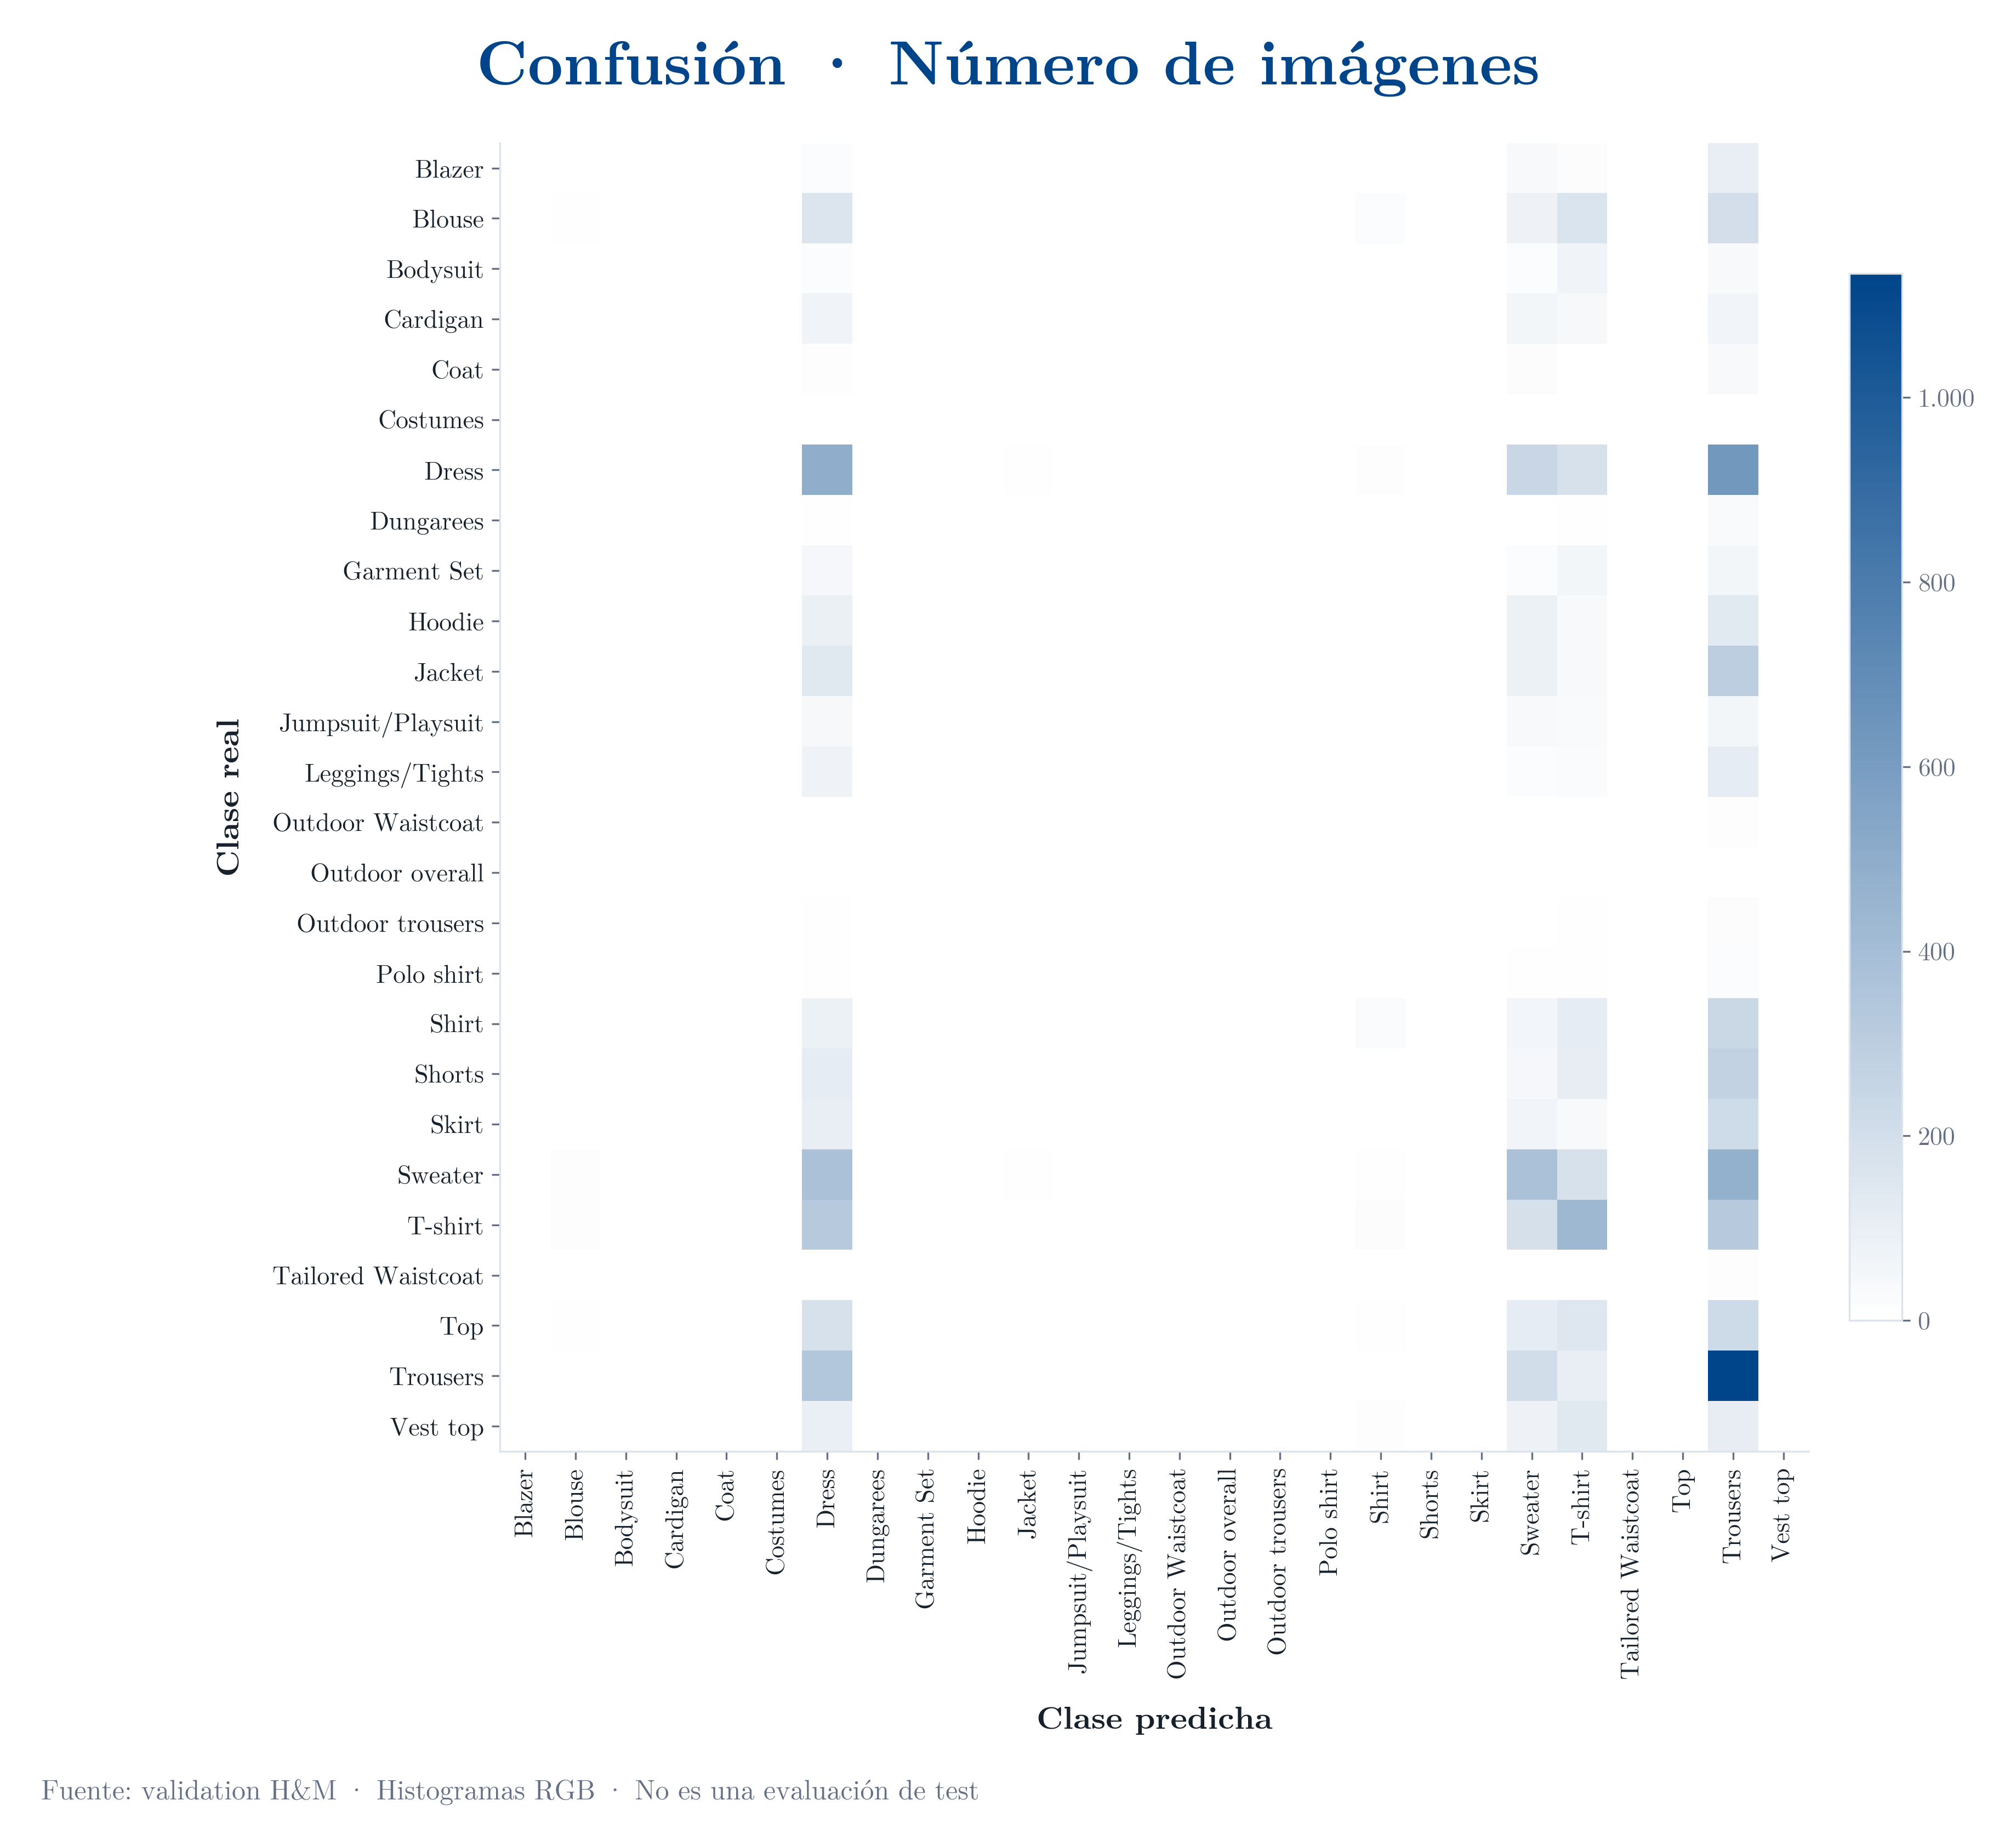

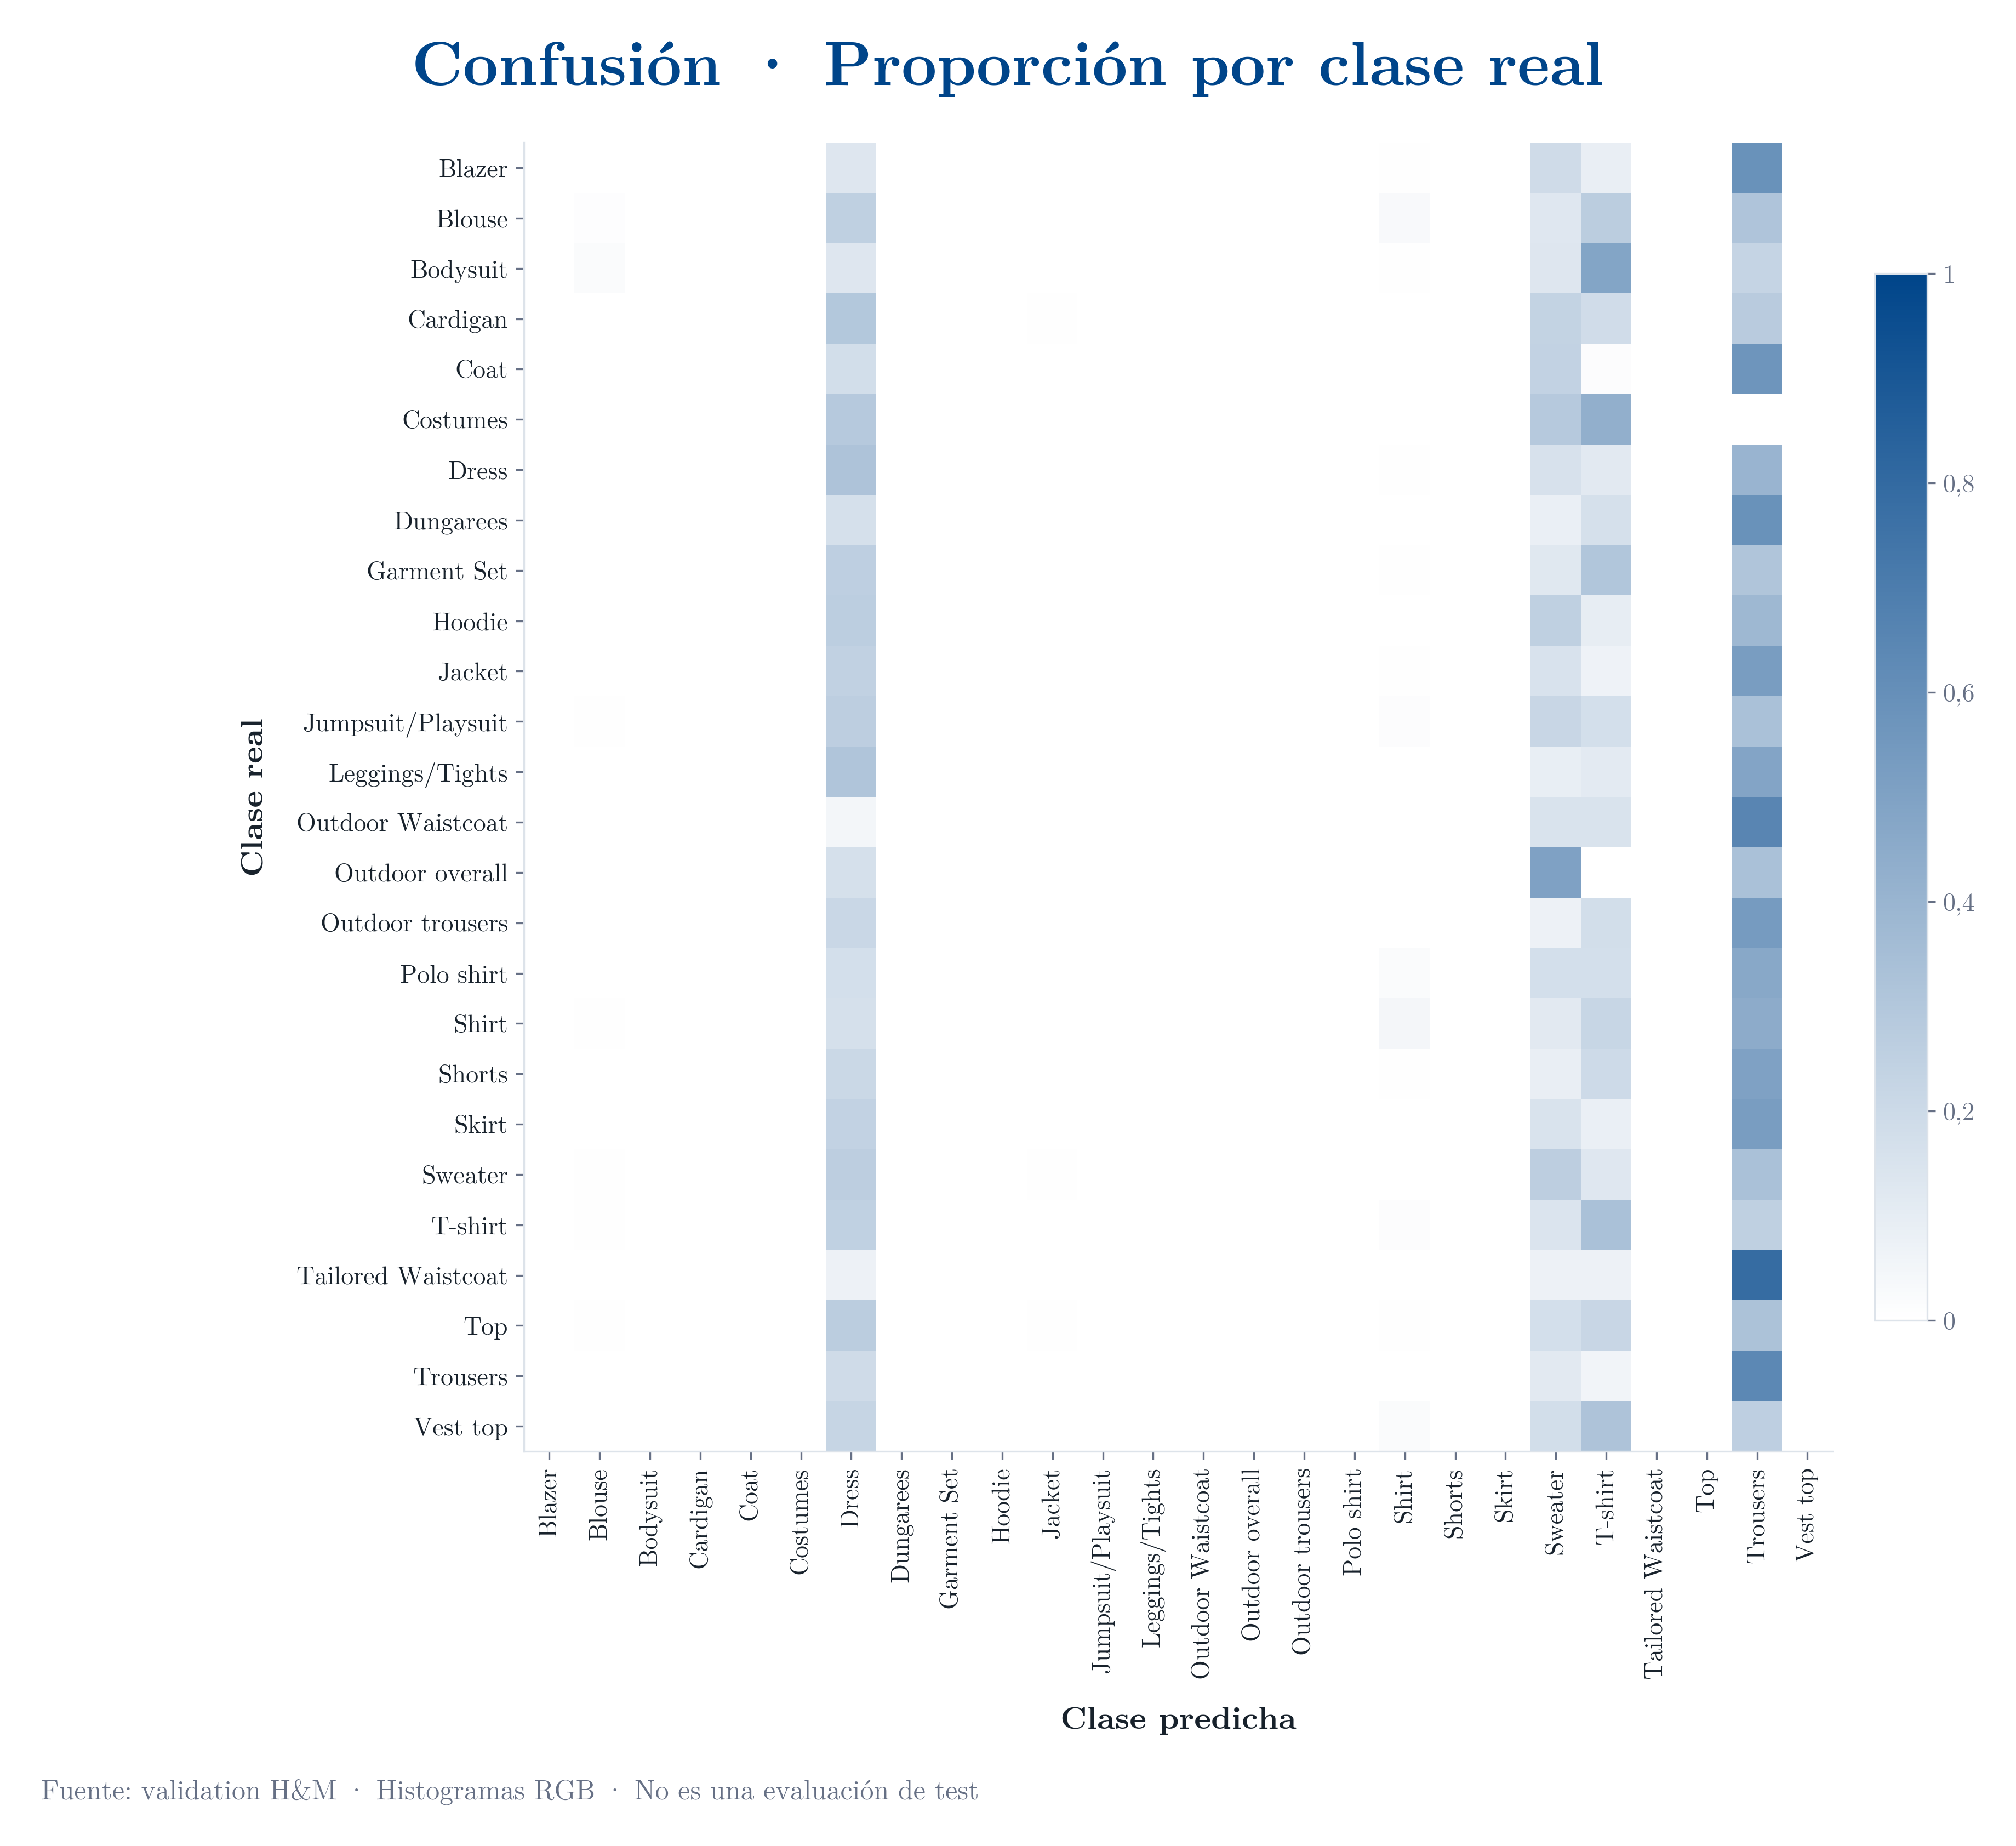

Real,Predicha,Errores,Fraccion_clase
Dress,Trousers,623,"0,399"
Sweater,Trousers,480,"0,336"
Sweater,Dress,374,"0,262"
Trousers,Dress,337,"0,189"
T-shirt,Trousers,326,"0,251"
T-shirt,Dress,322,"0,248"
Jacket,Trousers,295,"0,521"
Shorts,Trousers,273,"0,503"
Dress,Sweater,248,"0,159"
Shirt,Trousers,236,"0,448"


In [11]:
from IPython.display import Image as DisplayImage
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import confusion_matrix

cm=confusion_matrix(val_y,predictions['Logística de color'],labels=np.arange(len(names)))
row_totals=cm.sum(axis=1,keepdims=True)
cm_normalized=np.divide(cm,row_totals,out=np.zeros_like(cm,dtype=float),where=row_totals>0)
blue_scale=LinearSegmentedColormap.from_list('etsit_confusion',['#FFFFFF','#00458A'])
# Dos salidas independientes: cada matriz dispone del ancho del notebook.
for values,title,suffix,upper in [
    (cm,'Confusión · Número de imágenes','counts',None),
    (cm_normalized,'Confusión · Proporción por clase real','proportions',1),
]:
    fig,ax=plt.subplots(figsize=(12,11))
    image=ax.imshow(values,cmap=blue_scale,vmin=0,vmax=upper)
    ax.set_xticks(range(len(names)),names,rotation=90,ha='center',fontsize=11,color='#17212B')
    ax.set_yticks(range(len(names)),names,fontsize=11,color='#17212B')
    ax.set_xlabel('Clase predicha',fontsize=14)
    ax.set_ylabel('Clase real',fontsize=14)
    ax.grid(False)
    fig.suptitle(title,color='#00458A')
    bar=fig.colorbar(image,ax=ax,shrink=.8,pad=.025)
    bar.ax.tick_params(labelsize=11)
    name=f'03_colour_confusion_{suffix}'
    save_figure(fig,ROOT,name,'Fuente: validation H&M · Histogramas RGB · No es una evaluación de test')
    display(DisplayImage(filename=str(ROOT/f'results/figures/data/{name}.png'),width=950))
    plt.close(fig)
pairs=pd.DataFrame([{'Real':names[i],'Predicha':names[j],'Errores':int(cm[i,j]),'Fraccion_clase':float(cm_normalized[i,j])} for i in range(len(names)) for j in range(len(names)) if i!=j]).sort_values('Errores',ascending=False)
display(styled(pairs.head(12),3))

## 8. Qué sabemos y qué falta

La muestra visual de hasta ocho grupos de train por tipo, la composición comercial y los descriptores ayudan a estudiar diferencias entre prendas. Las anotaciones humanas pendientes no son una revisión terminada. Los dos baselines se miden en validation con intervalos que remuestrean productos completos.

La distribución desigual de clases forma parte del problema: por eso leemos macro-F1, accuracy y resultados por clase juntos. Los pesos o el balance del sampler son hipótesis de entrenamiento, no excusas para eliminar fotos válidas.

El siguiente notebook mide tiempo y memoria de una época piloto antes de decidir si el coste exige una muestra de train. Si cabe entrenar con toda la cohorte, se conserva completa. El test predictivo permanece cerrado.